# 01 — Analyse exploratoire du jeu C-MAPSS

**Objectif** : comprendre les données avant de construire un modèle. Quels capteurs portent l'information sur l'usure, à partir de quand la dégradation est-elle visible, et qu'est-ce qui rend FD004 plus difficile que FD001 ?

**Données** : C-MAPSS, jeu simulé publié par la NASA (Saxena et al., 2008). Chaque moteur démarre en bon état, se dégrade, puis tombe en panne. Une ligne = un moteur à un cycle de vol.

| Sous-ensemble | Moteurs (train) | Conditions de vol | Modes de panne |
| --- | --- | --- | --- |
| FD001 | 100 | 1 | 1 (compresseur haute pression) |
| FD004 | 249 | 6 | 2 (compresseur haute pression, soufflante) |

**Questions posées**
1. Les données sont-elles propres ?
2. Quels capteurs portent de l'information ?
3. L'usure du compresseur produit-elle les tendances que la physique laisse attendre ?
4. À partir de quand la dégradation est-elle visible dans les signaux ?
5. Qu'est-ce qui change sur FD004 ?

Chaque section répond à une question. Les chiffres cités dans les textes sont produits par le code (phrases en sortie de cellule) : ils restent justes si les données changent.

**Sommaire** : 1. Chargement · 2. Qualité · 3. Durées de vie · 4. Capteurs utiles · 5. Trajectoires de dégradation · 6. Corrélations · 7. Bruit · 8. FD004 et ses six régimes · 9. Conclusion

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook est rangé dans notebooks/ : on se place à la racine du projet,
# pour que les chemins relatifs (data/raw, results, models) fonctionnent partout.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import set_plot_style

set_plot_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def say(text: str) -> None:
    """Affiche une phrase dont les chiffres viennent du code, pas d'une saisie manuelle."""
    from IPython.display import Markdown, display

    display(Markdown(text))

import seaborn as sns

from src.data import SENSOR_NAMES, SETTINGS, add_rul, fit_scaler, load_cmapss

## 1. Chargement

Les fichiers n'ont pas d'en-tête et leurs colonnes sont séparées par des espaces. `load_cmapss` (dans `src/data.py`) nomme les 26 colonnes :

| Colonnes | Contenu |
| --- | --- |
| `unit` | Numéro du moteur |
| `cycle` | Numéro du cycle de vol |
| `setting_1` à `setting_3` | Réglages opérationnels (altitude, Mach, manette des gaz) |
| `s1` à `s21` | Mesures des 21 capteurs (températures, pressions, vitesses, débits) |

In [2]:
df = load_cmapss("FD001")
print(f"{df.shape[0]} lignes x {df.shape[1]} colonnes, {df['unit'].nunique()} moteurs")
df.head()

20631 lignes x 26 colonnes, 100 moteurs


,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Contrôles de qualité

Trois vérifications, écrites avec `assert` : si l'une échoue, le notebook s'arrête au lieu d'afficher un chiffre que personne ne remarquerait.

1. Aucune valeur manquante.
2. Aucune ligne en double.
3. Pour chaque moteur, les cycles valent 1, 2, 3, ..., n sans trou. C'est cette condition qui permet d'affirmer que la durée de vie d'un moteur est son cycle maximal.

In [3]:
assert df.isna().sum().sum() == 0, "Le jeu contient des valeurs manquantes"
assert df.duplicated().sum() == 0, "Le jeu contient des lignes en double"


def cycles_consecutifs(cycles: pd.Series) -> bool:
    """Vrai si les cycles d'un moteur valent exactement 1, 2, ..., n dans cet ordre."""
    return np.array_equal(cycles.to_numpy(), np.arange(1, len(cycles) + 1))


ok_par_moteur = df.groupby("unit")["cycle"].apply(cycles_consecutifs)
assert ok_par_moteur.all(), f"Cycles non consécutifs : {ok_par_moteur[~ok_par_moteur].index.tolist()}"

print("Contrôles réussis : aucune valeur manquante, aucun doublon, cycles consécutifs.")

Contrôles réussis : aucune valeur manquante, aucun doublon, cycles consécutifs.


## 3. Durées de vie des moteurs

Dans le jeu d'entraînement, chaque moteur fonctionne jusqu'à la panne.

min     128.0
mean    206.0
50%     199.0
max     362.0


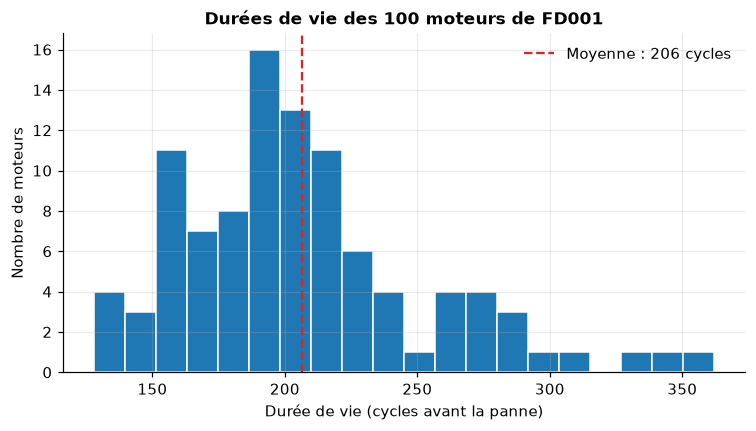

Les durées de vie vont de **128 à 362 cycles** (moyenne 206) : le moteur le plus endurant vit 2.8 fois plus longtemps que le moins endurant. Tous les moteurs vivent au moins 128 cycles, donc une fenêtre de 30 à 40 cycles convient à chacun.

In [4]:
lifetimes = df.groupby("unit")["cycle"].max()
print(lifetimes.describe()[["min", "mean", "50%", "max"]].round(0).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lifetimes, bins=20, edgecolor="white")
ax.axvline(lifetimes.mean(), color="tab:red", linestyle="--", label=f"Moyenne : {lifetimes.mean():.0f} cycles")
ax.set_xlabel("Durée de vie (cycles avant la panne)")
ax.set_ylabel("Nombre de moteurs")
ax.set_title("Durées de vie des 100 moteurs de FD001")
ax.legend()
plt.show()

say(f"Les durées de vie vont de **{lifetimes.min()} à {lifetimes.max()} cycles** (moyenne {lifetimes.mean():.0f}) : "
    f"le moteur le plus endurant vit {lifetimes.max() / lifetimes.min():.1f} fois plus longtemps que le moins endurant. "
    f"Tous les moteurs vivent au moins {lifetimes.min()} cycles, donc une fenêtre de 30 à 40 cycles convient à chacun.")

**Conséquence** : la RUL brute est très élevée en début de vie, alors qu'un moteur neuf ne montre encore aucun signe d'usure. La question 4 dira à partir de quand les signaux portent une information.

## 4. Quels capteurs portent de l'information ?

L'écart-type seul est trompeur, car il dépend de l'unité de mesure : s9 (une vitesse en tr/min) a un écart-type d'environ 22, s15 (un rapport sans unité) d'environ 0,04. On compte donc aussi les **valeurs distinctes** : une colonne qui n'en a qu'une est constante.

In [5]:
variability = pd.DataFrame({
    "écart-type": df.std(),
    "valeurs distinctes": df.nunique(),
}).drop(index=["unit", "cycle"])
variability.sort_values("valeurs distinctes").head(12)

,écart-type,valeurs distinctes
s1,0.000000e+00,1
setting_3,0.000000e+00,1
s5,5.329200e-15,1
s10,0.000000e+00,1
s18,0.000000e+00,1
s19,0.000000e+00,1
s16,3.469531e-18,1
s6,1.388985e-03,2
s17,1.548763e+00,13
setting_2,2.930621e-04,13


**Lecture**
1. **Constantes** (une seule valeur) : s1, s5, s10, s16, s18, s19 et setting_3. Elles sont retirées.
2. **s6** ne prend que 2 valeurs (21,60 et 21,61) : c'est un effet d'arrondi, pas une usure progressive. Retiré.
3. **setting_1 et setting_2** oscillent autour de zéro. FD001 n'a qu'une condition de vol : c'est du bruit. Ils sont retirés pour FD001, mais serviront à identifier les régimes de FD004.

In [6]:
constant_cols = variability.index[variability["valeurs distinctes"] == 1].tolist()
drop_cols = constant_cols + ["s6", "setting_1", "setting_2"]
SENSORS = [c for c in df.columns if c[0] == "s" and c[1:].isdigit() and c not in drop_cols]

assert SENSORS == list(SENSOR_NAMES), "La liste doit correspondre à celle de src/data.py"
print(f"{len(SENSORS)} capteurs conservés :")
pd.Series(SENSOR_NAMES, name="grandeur mesurée").to_frame()

14 capteurs conservés :


,grandeur mesurée
s2,T24 — température sortie compresseur BP
s3,T30 — température sortie compresseur HP
s4,T50 — température sortie turbine BP
s7,P30 — pression totale sortie compresseur HP
s8,Nf — vitesse de la soufflante
s9,Nc — vitesse du cœur
s11,Ps30 — pression statique sortie compresseur HP
s12,phi — débit carburant / Ps30
s13,NRf — vitesse corrigée de la soufflante
s14,NRc — vitesse corrigée du cœur


## 5. Trajectoires de dégradation

**Hypothèse physique** : FD001 simule l'usure du compresseur haute pression. Un compresseur usé comprime moins bien ; pour fournir la même poussée, le moteur brûle plus de carburant. Les températures en aval (T30, T50) et la pression statique Ps30 devraient **monter**, la pression totale P30 et les débits de refroidissement (W31, W32) devraient **descendre**.

Pour comparer des moteurs de durées de vie différentes, on aligne les courbes **sur la panne** : l'axe horizontal est le nombre de cycles restants. Alignées sur le début de vie, les pannes tomberaient à des abscisses différentes et les courbes se brouilleraient là où se trouve l'information.

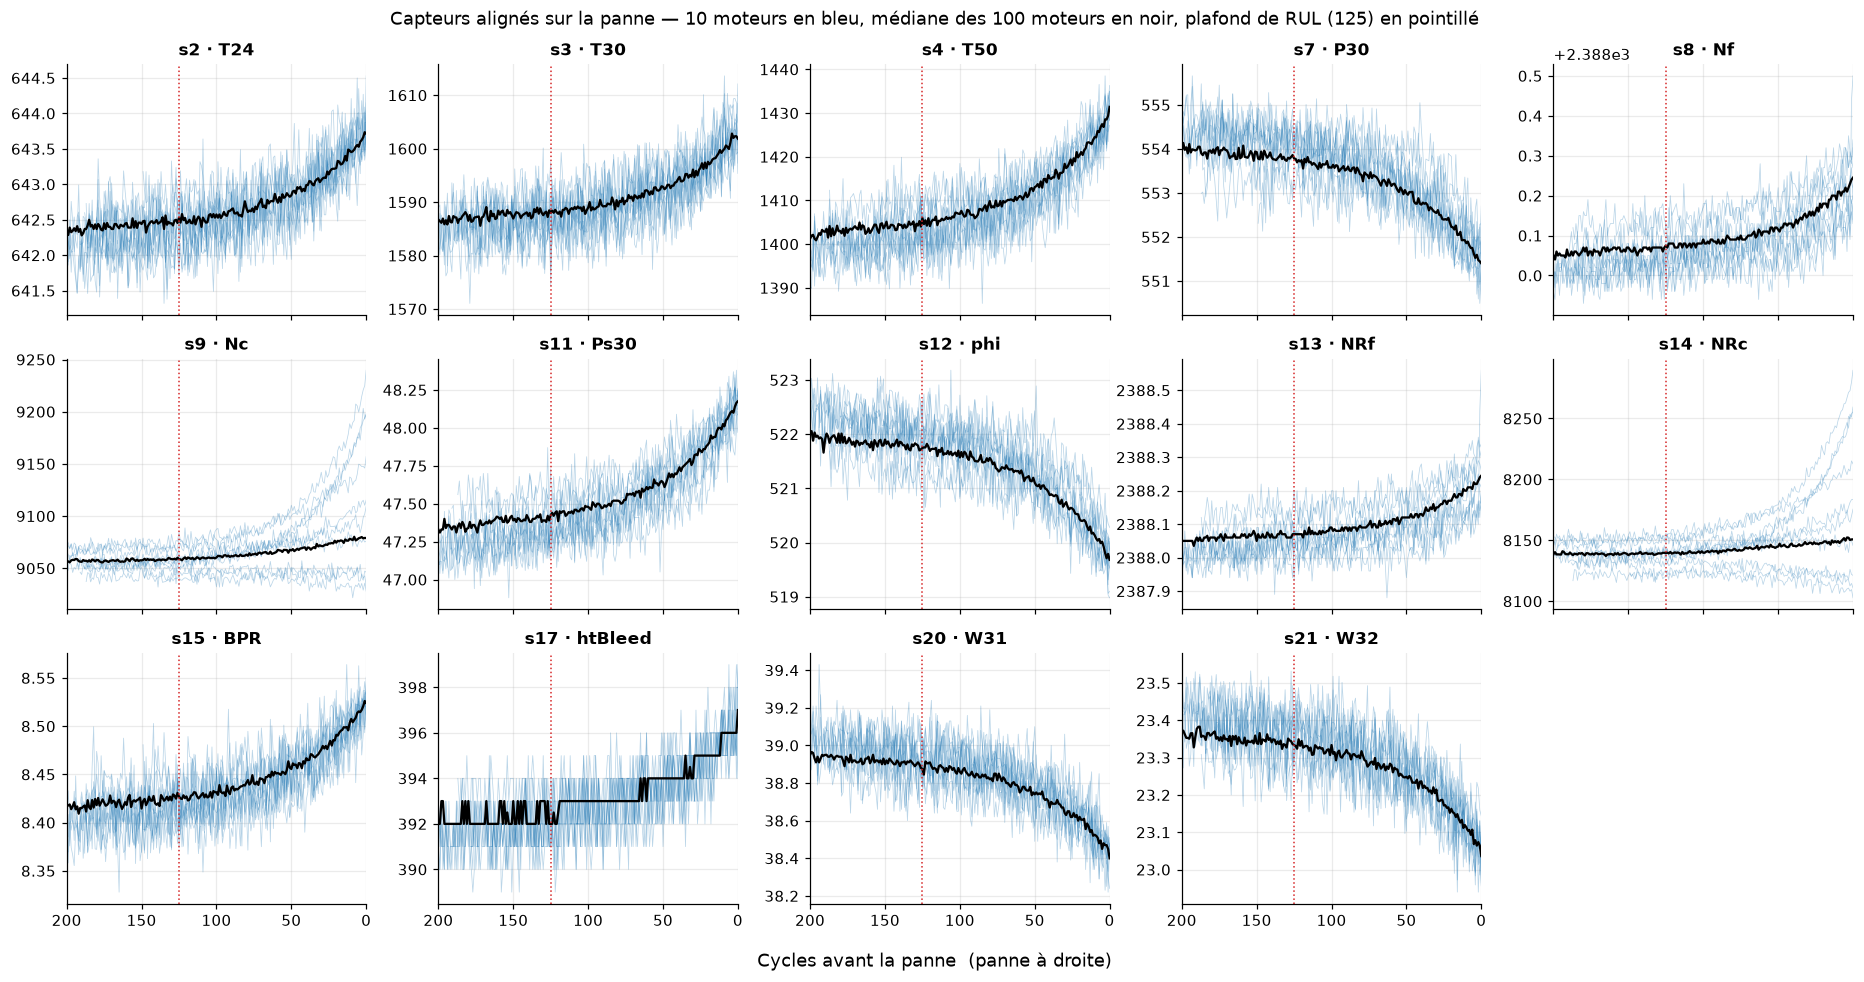

In [7]:
df["cycles_avant_panne"] = df.groupby("unit")["cycle"].transform("max") - df["cycle"]
recent = df[df["cycles_avant_panne"] <= 200]
median = recent.groupby("cycles_avant_panne")[SENSORS].median().sort_index(ascending=False)

fig, axes = plt.subplots(3, 5, figsize=(17, 9), sharex=True)
for ax, sensor in zip(axes.flat, SENSORS):
    for unit in range(1, 11):
        engine = recent[recent["unit"] == unit]
        ax.plot(engine["cycles_avant_panne"], engine[sensor], color="tab:blue", linewidth=0.5, alpha=0.3)
    ax.plot(median.index, median[sensor], color="black", linewidth=1.5)
    ax.axvline(125, color="tab:red", linestyle=":", linewidth=1)
    ax.set_title(f"{sensor} · {SENSOR_NAMES[sensor].split(' — ')[0]}")
axes.flat[-1].axis("off")
axes[0, 0].set_xlim(200, 0)  # axe partagé : la panne (0) est à droite
fig.supxlabel("Cycles avant la panne  (panne à droite)")
fig.suptitle("Capteurs alignés sur la panne — 10 moteurs en bleu, médiane des 100 moteurs en noir, plafond de RUL (125) en pointillé")
plt.tight_layout()
plt.show()

### Vérification de l'hypothèse physique

L'hypothèse a été posée avant de regarder les courbes. On la confronte au sens de variation observé : la différence entre la médiane des 20 derniers cycles et celle des cycles situés à plus de 125 cycles de la panne, exprimée en écarts-types du capteur.

In [8]:
attendu = {"s3": "monte", "s4": "monte", "s11": "monte", "s7": "descend", "s20": "descend", "s21": "descend"}

fin = df[df["cycles_avant_panne"] < 20][SENSORS].median()
debut = df[df["cycles_avant_panne"] > 125][SENSORS].median()
variation = ((fin - debut) / df[SENSORS].std()).rename("variation (écarts-types)")

verif = variation.round(2).to_frame()
verif["observé"] = np.where(variation > 0, "monte", "descend")
verif["attendu"] = pd.Series(attendu)
verif["verdict"] = np.where(verif["attendu"].isna(), "pas d'hypothèse",
                            np.where(verif["attendu"] == verif["observé"], "conforme", "contraire"))
verif.insert(0, "grandeur", [SENSOR_NAMES[s].split(" — ")[0] for s in verif.index])
display(verif)

testes = verif[verif["attendu"].notna()]
say(f"**{(testes['verdict'] == 'conforme').sum()} capteurs sur {len(testes)}** varient dans le sens attendu. "
    f"Sans hypothèse préalable, {(variation > 0).sum()} capteurs montent et {(variation < 0).sum()} descendent ; "
    f"la variation la plus forte est celle de {variation.abs().idxmax()} ({variation[variation.abs().idxmax()]:+.1f} écart-type).")

plat = (median.loc[200:126].std() / median.loc[60:0].std()).median()
say(f"Entre 200 et 125 cycles avant la panne, la médiane des capteurs varie {1 / plat:.0f} fois moins que dans les "
    f"60 derniers cycles (rapport médian sur les 14 capteurs).")

,grandeur,variation (écarts-types),observé,attendu,verdict
s2,T24,2.16,monte,NaN,pas d'hypothèse
s3,T30,2.07,monte,monte,conforme
s4,T50,2.44,monte,monte,conforme
s7,P30,-2.38,descend,descend,conforme
s8,Nf,1.97,monte,NaN,pas d'hypothèse
s9,Nc,0.90,monte,NaN,pas d'hypothèse
s11,Ps30,2.51,monte,monte,conforme
s12,phi,-2.41,descend,NaN,pas d'hypothèse
s13,NRf,1.95,monte,NaN,pas d'hypothèse
s14,NRc,0.56,monte,NaN,pas d'hypothèse


**6 capteurs sur 6** varient dans le sens attendu. Sans hypothèse préalable, 10 capteurs montent et 4 descendent ; la variation la plus forte est celle de s17 (+2.6 écart-type).

Entre 200 et 125 cycles avant la panne, la médiane des capteurs varie 5 fois moins que dans les 60 derniers cycles (rapport médian sur les 14 capteurs).

**Lecture**
- L'hypothèse physique tient pour les capteurs sur lesquels elle se prononçait.
- s9 et s14 (vitesses du cœur) montent en médiane, mais avec une forte dispersion d'un moteur à l'autre : certaines courbes bleues descendent.
- Réponse à la question 4 : loin de la panne, les médianes sont presque plates. **Les signaux ne permettent pas de distinguer une RUL de 150 d'une RUL de 300.** C'est ce qui justifie de plafonner la cible ; la valeur de 125, courante dans la littérature, est cohérente avec ces courbes mais n'a pas été optimisée ici.

## 6. Corrélations

Deux questions : quels capteurs sont redondants entre eux, et lesquels suivent la RUL ? On utilise la RUL plafonnée à 125, qui sera la cible des modèles.

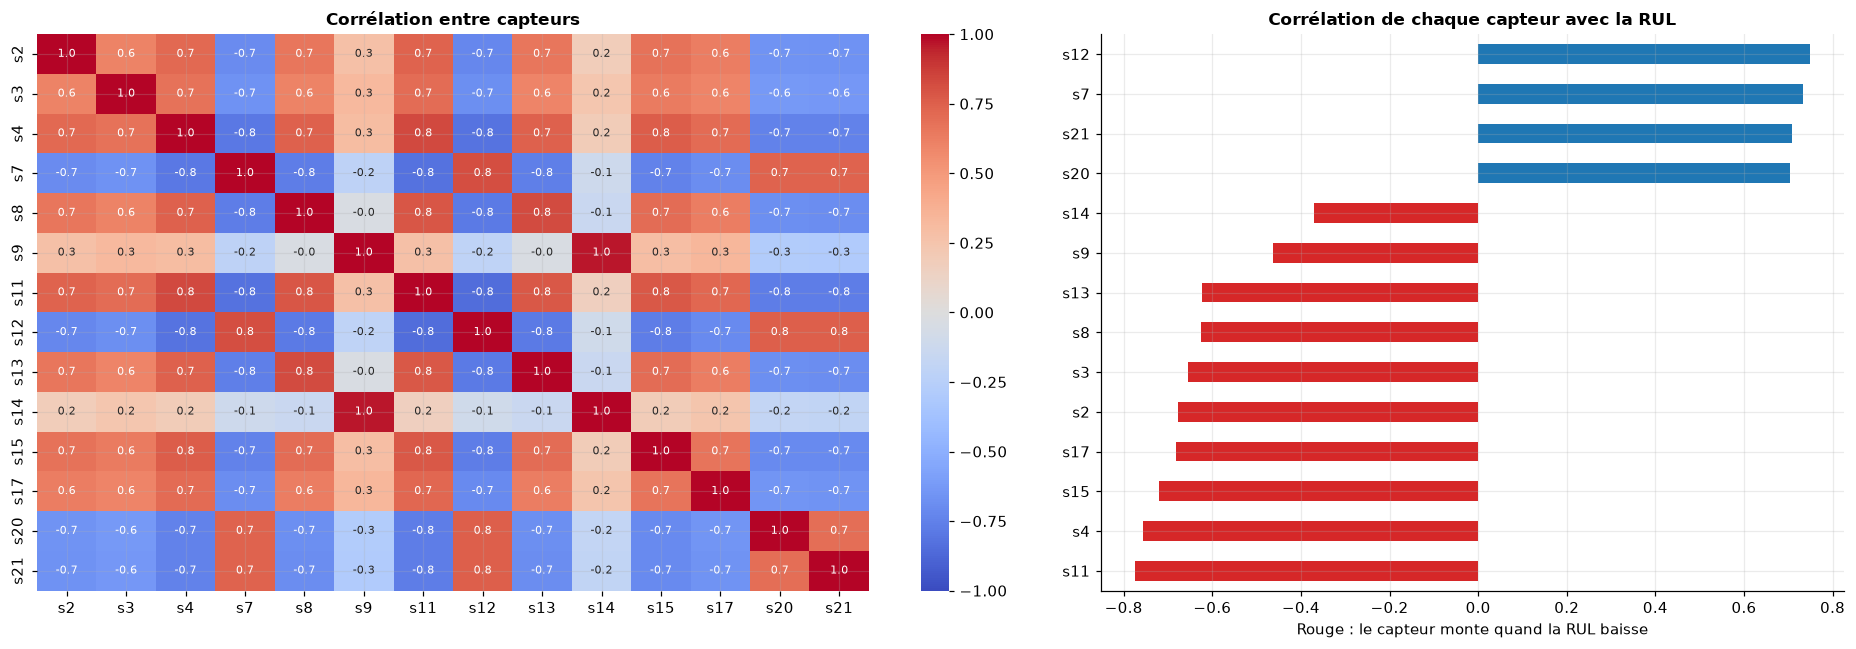

Capteurs les plus liés à la RUL : **s11** (-0.78), **s4** (-0.76), **s12** (+0.75), **s7** (+0.73). Les moins liés : s14 (-0.37) et s9 (-0.46).

Paire la plus redondante : **s9 et s14**, corrélés à 0.96.

In [9]:
df["rul"] = df["cycles_avant_panne"].clip(upper=125)

fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(df[SENSORS].corr(), cmap="coolwarm", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=axes[0])
axes[0].set_title("Corrélation entre capteurs")

corr_rul = df[SENSORS].corrwith(df["rul"]).sort_values()
corr_rul.plot.barh(ax=axes[1], color=np.where(corr_rul < 0, "tab:red", "tab:blue"))
axes[1].set_title("Corrélation de chaque capteur avec la RUL")
axes[1].set_xlabel("Rouge : le capteur monte quand la RUL baisse")
plt.tight_layout()
plt.show()

top = corr_rul.abs().sort_values(ascending=False)
pairs = df[SENSORS].corr().abs().where(np.triu(np.ones((len(SENSORS),) * 2, dtype=bool), k=1)).stack()
a, b = pairs.idxmax()
say("Capteurs les plus liés à la RUL : " + ", ".join(f"**{s}** ({corr_rul[s]:+.2f})" for s in top.index[:4])
    + f". Les moins liés : {top.index[-1]} ({corr_rul[top.index[-1]]:+.2f}) et {top.index[-2]} ({corr_rul[top.index[-2]]:+.2f}).")
say(f"Paire la plus redondante : **{a} et {b}**, corrélés à {pairs.max():.2f}.")

**Lecture**
- Les capteurs les plus liés à la RUL sont ceux que l'hypothèse physique désignait (pressions et températures du cœur).
- La paire la plus redondante est aussi la moins liée à la RUL. Faut-il en retirer un des deux ? Pour une régression linéaire, deux variables presque colinéaires rendent les coefficients instables. Pour un réseau récurrent ou une forêt, la redondance ne pose pas de problème : on garde les deux.
- Limite : une corrélation ne mesure qu'un lien **linéaire**. Un capteur peu corrélé peut rester utile à un modèle non linéaire ; le notebook 04 le vérifie.

## 7. Bruit de mesure

Une moyenne glissante fait apparaître la tendance. Elle est calculée sur les cycles **passés** uniquement : une fenêtre centrée utiliserait des cycles futurs, ce qui serait une fuite d'information.

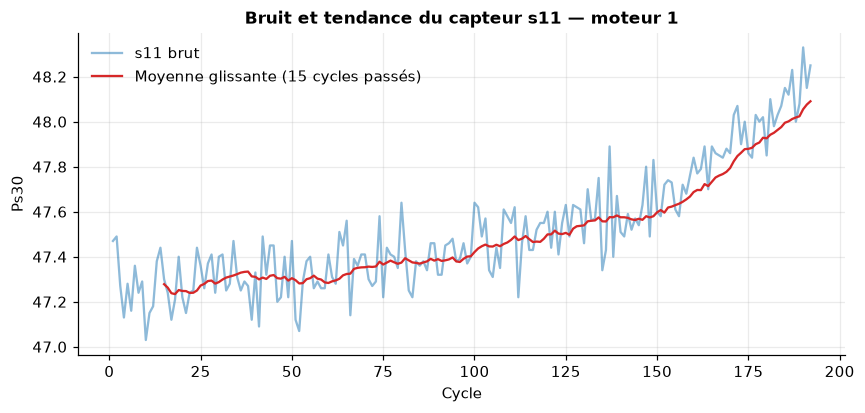

In [10]:
engine = df[df["unit"] == 1]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(engine["cycle"], engine["s11"], alpha=0.5, label="s11 brut")
ax.plot(engine["cycle"], engine["s11"].rolling(15).mean(), color="tab:red", label="Moyenne glissante (15 cycles passés)")
ax.set_xlabel("Cycle")
ax.set_ylabel(SENSOR_NAMES["s11"].split(" — ")[0])
ax.set_title("Bruit et tendance du capteur s11 — moteur 1")
ax.legend()
plt.show()

Le bruit est du même ordre que la variation du signal sur 20 à 30 cycles. Un seul cycle ne suffit pas à situer le moteur : il faut une **fenêtre** de cycles. Les modèles recevront tout de même les données brutes, car un réseau récurrent apprend lui-même à filtrer.

## 8. FD004 : six régimes de vol

FD004 contient 249 moteurs, 6 conditions de vol et 2 modes de panne. Les trois réglages opérationnels identifient le régime de vol de chaque cycle. On les regroupe avec un K-means à 6 groupes (`fit_scaler` dans `src/data.py`).

In [11]:
fd4 = add_rul(load_cmapss("FD004"))
vies = fd4.groupby("unit")["cycle"].max()
print(f"{fd4['unit'].nunique()} moteurs, {len(fd4)} lignes, durées de vie de {vies.min()} à {vies.max()} cycles")

scaler = fit_scaler(fd4, SENSORS, n_regimes=6)
fd4["regime"] = scaler.regimes(fd4)

regimes = fd4.groupby("regime")[SETTINGS].agg(["mean", "std"]).round(3)
regimes[("part des cycles", "")] = fd4["regime"].value_counts(normalize=True).round(2)
regimes

249 moteurs, 61249 lignes, durées de vie de 128 à 543 cycles


setting_1        setting_2        setting_3      part des cycles
            mean    std      mean    std      mean  std                
regime                                                                 
0         42.003  0.003     0.840  0.001     100.0  0.0            0.25
1         10.003  0.003     0.251  0.001     100.0  0.0            0.15
2         25.003  0.003     0.621  0.001      60.0  0.0            0.15
3          0.002  0.001     0.000  0.001     100.0  0.0            0.15
4         20.003  0.003     0.701  0.001     100.0  0.0            0.15
5         35.003  0.003     0.841  0.001     100.0  0.0            0.15

Les 6 groupes sont parfaitement séparés : dans chaque groupe, l'écart-type des réglages est quasi nul. Regardons maintenant un capteur le long de la vie d'un moteur, brut, puis normalisé par régime (moyenne et écart-type calculés séparément dans chaque régime).

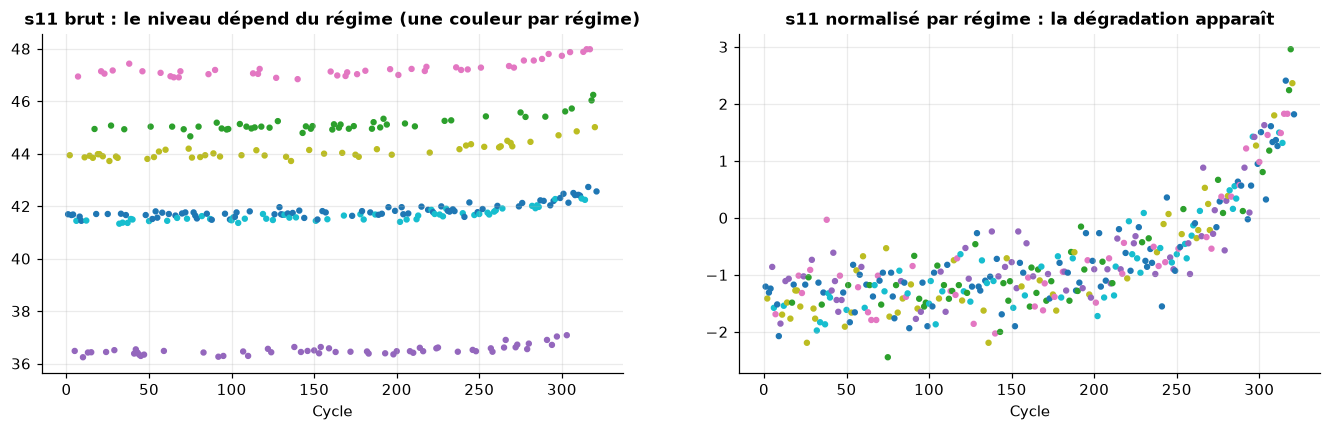

,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21
brut,-0.01,-0.04,-0.06,-0.00,-0.00,-0.03,-0.07,-0.01,-0.00,-0.10,0.00,-0.04,-0.00,-0.00
normalisé par régime,-0.58,-0.65,-0.72,-0.34,-0.57,-0.62,-0.76,-0.36,-0.57,-0.55,0.02,-0.67,0.02,0.03


En brut, la corrélation avec la RUL ne dépasse pas 0.10 en valeur absolue. Après normalisation par régime, elle atteint **-0.76 pour s11**. Capteurs qui restent sans lien linéaire avec la RUL sur FD004 : s15, s20, s21.

In [12]:
engine = fd4[fd4["unit"] == 1]
norm = scaler.transform(engine)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].scatter(engine["cycle"], engine["s11"], c=engine["regime"], cmap="tab10", s=10)
axes[0].set_title("s11 brut : le niveau dépend du régime (une couleur par régime)")
axes[1].scatter(norm["cycle"], norm["s11"], c=norm["regime"], cmap="tab10", s=10)
axes[1].set_title("s11 normalisé par régime : la dégradation apparaît")
for ax in axes:
    ax.set_xlabel("Cycle")
plt.show()

corr4 = pd.DataFrame({
    "brut": fd4[SENSORS].corrwith(fd4["rul"]),
    "normalisé par régime": scaler.transform(fd4)[SENSORS].corrwith(fd4["rul"]),
})
display(corr4.round(2).T)

best = corr4["normalisé par régime"].abs().idxmax()
muets = corr4.index[corr4["normalisé par régime"].abs() < 0.1].tolist()
say(f"En brut, la corrélation avec la RUL ne dépasse pas {corr4['brut'].abs().max():.2f} en valeur absolue. "
    f"Après normalisation par régime, elle atteint **{corr4.loc[best, 'normalisé par régime']:+.2f} pour {best}**. "
    f"Capteurs qui restent sans lien linéaire avec la RUL sur FD004 : {', '.join(muets)}.")

**Lecture**
- En brut, le niveau d'un capteur dépend presque uniquement du régime. Une normalisation globale, avec une seule moyenne par capteur, garderait ces sauts et laisserait la dégradation invisible. D'où l'hypothèse testée dans le notebook 03 : *la normalisation par régime est nécessaire sur FD004*.
- Certains capteurs informatifs sur FD001 ne le sont plus ici. Explication **possible, non vérifiée** : FD004 mélange deux modes de panne, qui pourraient pousser ces capteurs dans des sens opposés. Le jeu n'indique pas le mode de panne de chaque moteur, donc on ne peut pas le confirmer directement.

## 9. Conclusion

| Question | Réponse | Conséquence pour la suite |
| --- | --- | --- |
| Quels capteurs garder ? | 14 sur 21 : s2, s3, s4, s7, s8, s9, s11, s12, s13, s14, s15, s17, s20, s21 | Entrée des modèles |
| Lesquels sont les plus informatifs ? | Les pressions et températures du cœur (s11, s4, s12, s7) | À retrouver dans l'analyse d'importance du notebook 04 |
| Quand la dégradation est-elle visible ? | Dans la dernière partie de la vie ; avant, les médianes sont plates | RUL plafonnée à 125 |
| Faut-il un historique ? | Oui : le bruit est du même ordre que le signal | Fenêtres glissantes de 30 à 40 cycles |
| Qu'est-ce qui rend FD004 difficile ? | 6 régimes qui masquent la dégradation ; 2 modes de panne | Normalisation par régime, ajustée sur le train uniquement |

Suite : `02_baselines.ipynb` fixe les scores de référence.